In [13]:
# Настройка проекта
import matplotlib.pyplot as plt
import meep as mp
import conf
from lib import my_gui, my_decoders, my_sources
from lib import help_functions
import numpy as np
mp.verbosity(0) # decrease amount of output

0

In [14]:
from matplotlib import animation

# Simulation parameters for MEEP
D_aperture = 0.5*1e3
# D_gap = 0.117 * 1e3
D_pinhole = 0.1*1e3
max_angle_in_deg = 75
max_angle_in_rad = np.deg2rad(max_angle_in_deg)
source_angle_in_deg = 0
source_angle_in_rad = np.deg2rad(source_angle_in_deg)
# D_aperture = help_functions.find_Dfront(D_gap, D_pinhole, max_angle_in_deg)
x_whole = 0.2*1e3
cell = mp.Vector3(x_whole, D_aperture, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.pml, direction=mp.ALL, side=mp.ALL)]

from_pin_to_surf_gap = help_functions.get_gap_from_pinhole_to_surface(D_aperture, D_pinhole, max_angle_in_deg)

FloatProgress(value=0.0, description='0% done ', max=0.0)

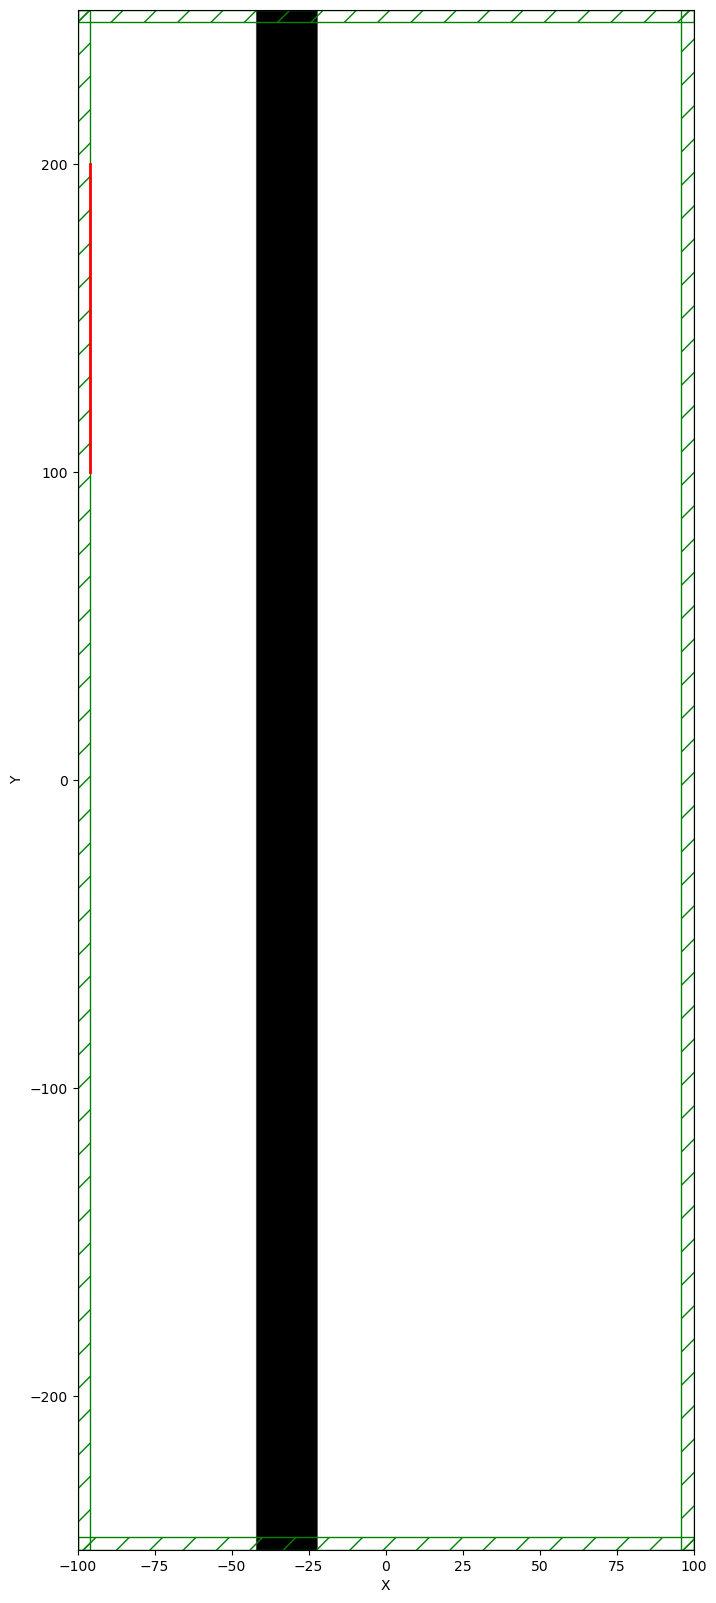

FloatProgress(value=0.0, description='0% done ', max=200.0)

Максимальная амплитуда поля: 0.33121973632953056


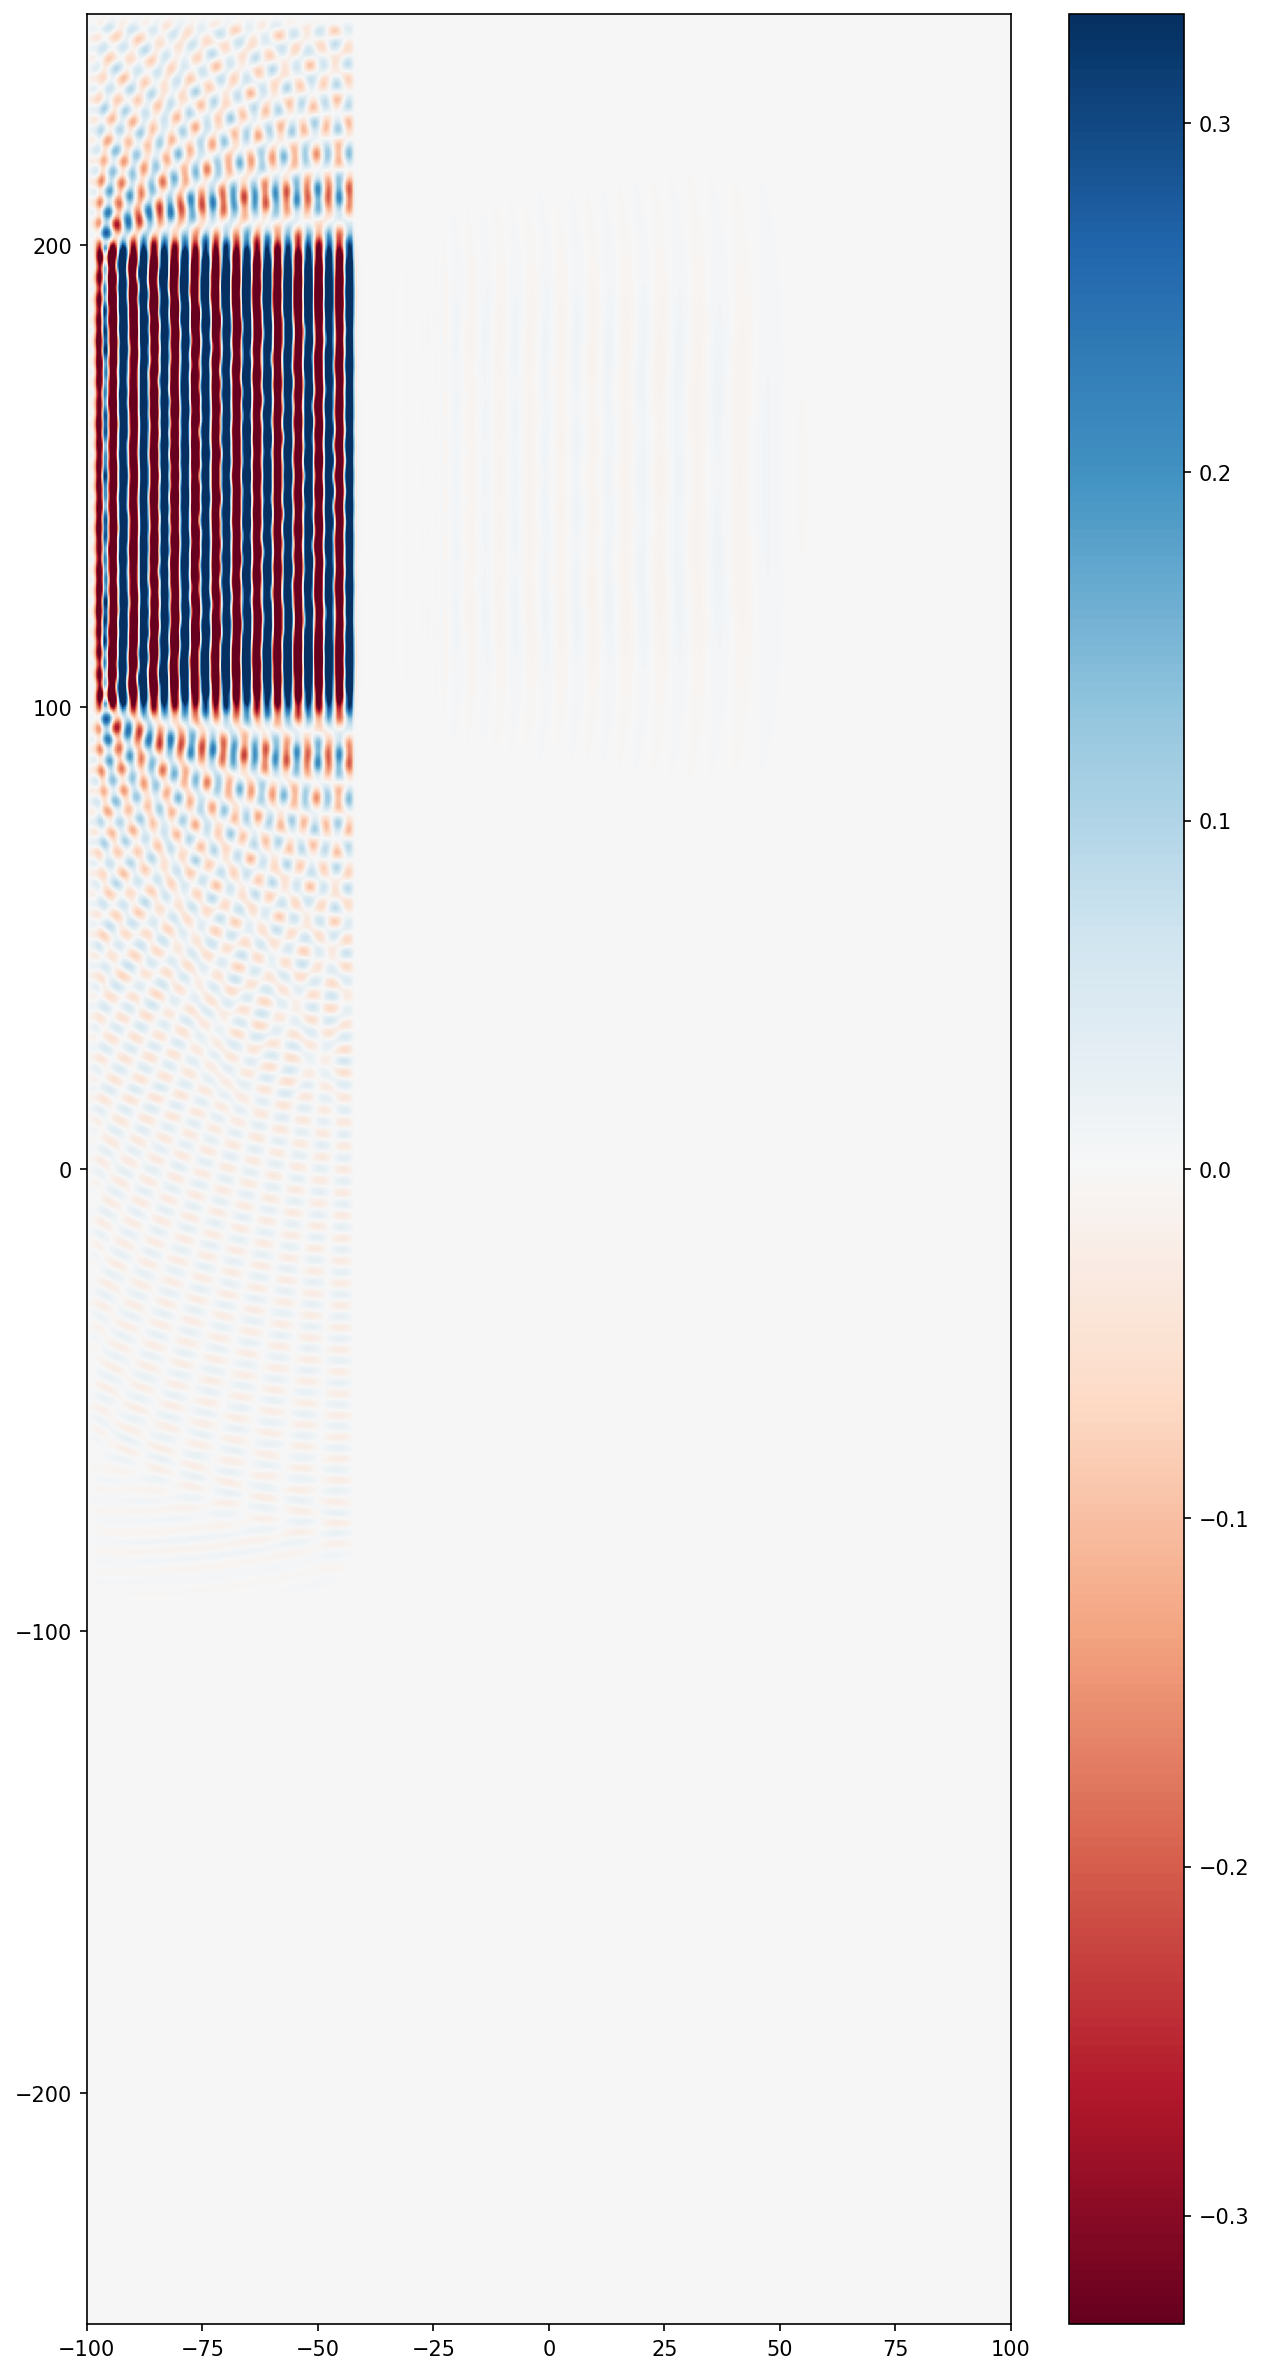

In [15]:
source_center = mp.Vector3(x = (-x_whole/2) + conf.pml, y = D_pinhole/2 + 0.1*1e3, z = 0)
sources_obj = my_sources.KvectorSource(diaphragm=D_pinhole, frequency= conf.inc_fcen, dfreq= conf.inc_df, center= source_center, angle_in_rad=source_angle_in_rad)
sources = sources_obj.get_sources()

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    sources=[sources],
    resolution=conf.min_resolution * 2,
    # symmetries = [mp.Mirror(mp.Y)],

)

sim.run(until=0)
fieldEz = np.array(sim.get_array(center=mp.Vector3(0,0,0), size=cell, component=mp.Ez)).T
fieldData = np.array([np.zeros(fieldEz.shape)])
def updateField(sim):
    global fieldData
    fieldEz = np.array([sim.get_array(center=mp.Vector3(0,0,0), size=cell, component=mp.Ez)])
    fieldEz = np.transpose(fieldEz, (0, 2, 1))
    fieldData = np.vstack((fieldData, fieldEz))

def animate(i):
    im.set_data(fieldData[i])
    return im,


geometry = [mp.Block(
    material=conf.in_material,
    size=mp.Vector3(0.02*1e3, mp.inf, 0),
    center=mp.Vector3(source_center.x + from_pin_to_surf_gap + 0.01*1e3),
)]

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=[sources],
    resolution=conf.min_resolution * 2,
    # symmetries = [mp.Mirror(mp.Y)],
)

plt.figure(figsize=(10, 20))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,0,0), size=mp.Vector3(cell[0],cell[1],0))
)
plt.show()  # Отображение изображения

animationTimestepDuration = 0.1
endTime = 200
# Running the simulation
sim.run(mp.at_every(animationTimestepDuration, updateField), until=endTime)
fieldData = np.real(fieldData)

# Автоматическая амплитуда по всем кадрам
abs_max = np.abs(fieldData).max()/4
print("Максимальная амплитуда поля:", abs_max)

fig, ax = plt.subplots(figsize=(10, 20), dpi=150)
im = ax.imshow(fieldData[0], cmap='RdBu',
               vmin=-abs_max, vmax=abs_max,
               extent=[-cell.x/2, +cell.x/2, -cell.y/2, +cell.y/2],
               origin='lower')
fig.colorbar(im)

fieldAnimation = animation.FuncAnimation(fig, animate, frames=fieldData.shape[0], blit=True)
fieldAnimation.save('KvectorSource_pinhole_simtest4.mp4', dpi=150, fps=15, extra_args=['-vcodec', 'libx264'])